# Day 1 — Option Basics & the Data Pipeline

**Implied Volatility Surface & Options Analysis** · Notebook 01

## 1. Project Overview & Theory

### Objective
Build a clean, reproducible dataset of real option quotes (SPY and AAPL) that later notebooks use to
price options with Black–Scholes, back out **implied volatility** for every contract, and fit an
arbitrage-checked **volatility surface**.

**Deliverable of today:** a clean DataFrame of option quotes (strike, maturity, mid price, type, spot)
saved in `data/`, so the rest of the project never needs to call yfinance again.

### Key vocabulary

| Term | Meaning |
|---|---|
| **Call** | The right (not obligation) to **buy** the underlying at the strike $K$ on expiry $T$. |
| **Put** | The right (not obligation) to **sell** the underlying at the strike $K$ on expiry $T$. |
| **Strike $K$** | The fixed price at which the option can be exercised. |
| **Premium** | The price paid today for the option ($C$ for a call, $P$ for a put). We use the **mid** $=(\text{bid}+\text{ask})/2$. |
| **Expiry $T$** | The date the option dies; in formulas $T$ is time to expiry in **years**. |
| **Bid / Ask** | Best price a buyer will pay / a seller will accept. The gap is the **spread** (a liquidity measure). |
| **Open interest** | Number of contracts still open. OI $=0$ means nobody holds it — usually a stale quote. |

### Payoffs at expiry (European options)
$$
C_T = (S_T - K)^+, \qquad P_T = (K - S_T)^+ ,
$$
where $x^+ = \max(x, 0)$ and $S_T$ is the underlying price at expiry.

### Forward and moneyness
With risk-free rate $r$ and dividend yield $q$, the forward price is $F = S e^{(r-q)T}$ and the
log-moneyness is
$$
k = \ln\frac{K}{F}.
$$
$k<0$: call in-the-money (put out-of-the-money); $k=0$: at-the-money forward.

### No-arbitrage bounds
$$
\max\!\left(Se^{-qT} - Ke^{-rT},\,0\right) \le C \le Se^{-qT}, \qquad
\max\!\left(Ke^{-rT} - Se^{-qT},\,0\right) \le P \le Ke^{-rT}.
$$

### Why keep only OTM options?
OTM options are the most liquid and their whole price is **time value**, so the implied volatility is
accurate. ITM options are mostly intrinsic value, so a small quote error becomes a large IV error.
**Rule:** puts for $K < S$, calls for $K \ge S$.

## 2. Library Imports

In [92]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# Project folders (works whether the notebook runs from src/ or the project root)
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

TICKERS = ["SPY", "AAPL"]
MAX_EXPIRIES = 10
MIN_DAYS, MAX_DAYS = 7, 730   # expiry window: skip the daily 0-6 DTE options, go out to ~2 years

# False -> load the saved files in data/ (no internet needed).
# True  -> download fresh quotes from yfinance and overwrite data/.
REFRESH = False

print("Project root:", ROOT)
print("Data folder :", DATA_DIR)

Project root: /Users/macbookpro/Documents/YEAR 5/Personal_Practice/Implied Volatility Surface & Options Analysis
Data folder : /Users/macbookpro/Documents/YEAR 5/Personal_Practice/Implied Volatility Surface & Options Analysis/data


## 3. Download Option Data

`fetch_chain` downloads `MAX_EXPIRIES` expiries for one ticker and stacks calls and puts into one
long table. SPY lists a new expiry almost **every day**, so "the first 10 expiries" would all be
within ~3 weeks. Instead `pick_expiries` spreads the 10 expiries evenly between 7 days and 2 years —
exactly the maturity range the volatility surface needs later. Time to expiry `T` is measured from the **download date** and stored in the
file, so reloading the data later gives exactly the same numbers.

`load_or_download` is the only function the rest of the project needs:
- if `data/raw_<TICKER>.parquet` exists and `REFRESH = False` → read it from disk;
- otherwise → download from yfinance and save it.

The risk-free rate (13-week T-bill, `^IRX`) and the spot are saved in `data/market_meta.json`.

> **Timing note.** yfinance quotes are delayed and can be stale outside US market hours
> (≈ 20:30–03:00 Phnom Penh time). Download during those hours, then work offline from the files.

In [93]:
def get_risk_free_rate():
    """13-week US T-bill yield (^IRX), as a decimal."""
    irx = yf.Ticker("^IRX").history(period="5d")["Close"].iloc[-1]
    return float(irx) / 100.0


def pick_expiries(expiries, today, n=MAX_EXPIRIES, min_days=MIN_DAYS, max_days=MAX_DAYS):
    """Choose n expiries spread evenly (by position) between min_days and max_days."""
    days = np.array([(pd.Timestamp(e) - today).days for e in expiries])
    ok = [e for e, dd in zip(expiries, days) if min_days <= dd <= max_days]
    if len(ok) <= n:
        return ok
    idx = np.unique(np.linspace(0, len(ok) - 1, n).round().astype(int))
    return [ok[i] for i in idx]


def fetch_chain(ticker="SPY", max_expiries=MAX_EXPIRIES):
    """Download calls and puts for `max_expiries` well-spread expiries into one DataFrame."""
    tk = yf.Ticker(ticker)
    spot = float(tk.history(period="1d")["Close"].iloc[-1])
    today = pd.Timestamp.today().normalize()
    frames = []
    for exp in pick_expiries(tk.options, today, max_expiries):
        chain = tk.option_chain(exp)
        for d, kind in [(chain.calls, "call"), (chain.puts, "put")]:
            d = d[["contractSymbol", "strike", "bid", "ask", "lastPrice", "volume",
                   "openInterest", "impliedVolatility"]].copy()
            d["type"] = kind
            d["expiry"] = pd.to_datetime(exp)
            frames.append(d)
    df = pd.concat(frames, ignore_index=True)
    df["ticker"] = ticker
    df["spot"] = spot
    df["download_date"] = today
    df["download_time"] = pd.Timestamp.now()
    df["T"] = (df["expiry"] - today).dt.days / 365.0
    df["mid"] = (df["bid"] + df["ask"]) / 2
    return df.rename(columns={"impliedVolatility": "iv_yahoo"})


META_PATH = DATA_DIR / "market_meta.json"


def load_meta():
    return json.loads(META_PATH.read_text()) if META_PATH.exists() else {}


def save_meta(meta):
    META_PATH.write_text(json.dumps(meta, indent=2))


def load_or_download(ticker, refresh=REFRESH):
    """Read data/raw_<ticker>.parquet if it exists, otherwise download and save it."""
    path = DATA_DIR / f"raw_{ticker}.parquet"
    meta = load_meta()
    if path.exists() and not refresh:
        print(f"[{ticker}] loaded from {path.name}")
        return pd.read_parquet(path)

    print(f"[{ticker}] downloading from yfinance ...")
    df = fetch_chain(ticker, MAX_EXPIRIES)
    df.to_parquet(path, index=False)
    # dated snapshot as well, so old data is never lost when refreshing
    df.to_parquet(DATA_DIR / f"raw_{ticker}_{df['download_date'].iloc[0]:%Y%m%d}.parquet", index=False)

    if refresh or "r" not in meta:
        meta["r"] = get_risk_free_rate()
    meta.setdefault("tickers", {})[ticker] = {
        "spot": float(df["spot"].iloc[0]),
        "download_date": f"{df['download_date'].iloc[0]:%Y-%m-%d}",
        "rows": len(df),
        "expiries": int(df["expiry"].nunique()),
    }
    save_meta(meta)
    print(f"[{ticker}] saved {len(df)} rows to {path.name}")
    return df

In [94]:
def has_live_quotes(df, min_share=0.5):
    """True if most contracts have a real bid/ask (False before/after US market hours)."""
    return ((df["bid"] > 0) & (df["ask"] > df["bid"])).mean() >= min_share


raw_data = {t: load_or_download(t) for t in TICKERS}
meta = load_meta()
r = meta["r"]

# Outside US trading hours yfinance returns bid = ask = 0. Then fall back to the last traded price
# (stale, but usable for exploring). Re-run with REFRESH = True during US hours to get real quotes.
LIVE = {}
for t, d in raw_data.items():
    LIVE[t] = has_live_quotes(d)
    if not LIVE[t]:
        d["mid"] = d["lastPrice"]
        print(f"WARNING [{t}]: only {(d['bid'] > 0).mean():.1%} of contracts have a bid "
              f"(downloaded {d['download_time'].iloc[0]:%Y-%m-%d %H:%M} local time, market closed?). "
              f"Using lastPrice as the price.")

print(f"\nrisk-free rate r = {r:.4f}")
for t, d in raw_data.items():
    print(f"{t:5s} spot = {d['spot'].iloc[0]:8.2f}   rows = {len(d):5d}   "
          f"expiries = {d['expiry'].nunique():2d}   downloaded = {d['download_date'].iloc[0]:%Y-%m-%d}")

[SPY] downloading from yfinance ...
[SPY] saved 3579 rows to raw_SPY.parquet
[AAPL] downloading from yfinance ...
[AAPL] saved 1247 rows to raw_AAPL.parquet
WARNING [SPY]: only 7.2% of contracts have a bid (downloaded 2026-10-21 18:39 local time, market closed?). Using lastPrice as the price.
WARNING [AAPL]: only 3.4% of contracts have a bid (downloaded 2026-10-21 18:39 local time, market closed?). Using lastPrice as the price.

risk-free rate r = 0.0408
SPY   spot =   769.05   rows =  3579   expiries = 10   downloaded = 2026-10-21
AAPL  spot =   339.50   rows =  1247   expiries = 10   downloaded = 2026-10-21


**Loading in any later notebook** (no yfinance needed):

```python
import json, pandas as pd
raw   = pd.read_parquet("../data/raw_SPY.parquet")     # full chain
clean = pd.read_parquet("../data/clean_SPY.parquet")   # filtered OTM quotes
r     = json.load(open("../data/market_meta.json"))["r"]
```

## 4. Explore Raw Data

Inspect calls and puts and look at the columns that matter: **bid, ask, strike, expiry, open interest**.

In [95]:
raw = raw_data["SPY"]
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3579 entries, 0 to 3578
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   contractSymbol  3579 non-null   object        
 1   strike          3579 non-null   float64       
 2   bid             3579 non-null   float64       
 3   ask             3579 non-null   float64       
 4   lastPrice       3579 non-null   float64       
 5   volume          3426 non-null   float64       
 6   openInterest    3579 non-null   int64         
 7   iv_yahoo        3579 non-null   float64       
 8   type            3579 non-null   object        
 9   expiry          3579 non-null   datetime64[ns]
 10  ticker          3579 non-null   object        
 11  spot            3579 non-null   float64       
 12  download_date   3579 non-null   datetime64[us]
 13  download_time   3579 non-null   datetime64[us]
 14  T               3579 non-null   float64       
 15  mid 

In [96]:
print("Calls (first expiry, around the money):")
S0 = raw["spot"].iloc[0]
first_exp = raw["expiry"].min()
cols = ["strike", "bid", "ask", "mid", "lastPrice", "volume", "openInterest", "iv_yahoo", "expiry", "T"]
near = raw[(raw["expiry"] == first_exp) & (raw["strike"].between(S0 * 0.98, S0 * 1.02))]
display(near[near["type"] == "call"][cols].head(10))
print("Puts (first expiry, around the money):")
display(near[near["type"] == "put"][cols].head(10))

Calls (first expiry, around the money):


,strike,bid,ask,mid,lastPrice,volume,openInterest,iv_yahoo,expiry,T
8,755.0,0.0,0.0,14.95,14.95,1.0,53,0.00001,2026-10-28,0.019178
9,756.0,0.0,0.0,15.92,15.92,9.0,13,0.00001,2026-10-28,0.019178
10,757.0,0.0,0.0,15.45,15.45,4.0,12,0.00001,2026-10-28,0.019178
11,758.0,0.0,0.0,13.99,13.99,96.0,25,0.00001,2026-10-28,0.019178
12,759.0,0.0,0.0,13.55,13.55,10.0,21,0.00001,2026-10-28,0.019178
13,760.0,0.0,0.0,13.01,13.01,23.0,277,0.00001,2026-10-28,0.019178
14,761.0,0.0,0.0,11.33,11.33,19.0,137,0.00001,2026-10-28,0.019178
15,762.0,0.0,0.0,10.95,10.95,58.0,153,0.00001,2026-10-28,0.019178
16,763.0,0.0,0.0,10.46,10.46,24.0,158,0.00001,2026-10-28,0.019178
17,764.0,0.0,0.0,9.54,9.54,55.0,148,0.00001,2026-10-28,0.019178


Puts (first expiry, around the money):


,strike,bid,ask,mid,lastPrice,volume,openInterest,iv_yahoo,expiry,T
129,754.0,0.0,0.0,1.68,1.68,157.0,539,0.031260,2026-10-28,0.019178
130,755.0,0.0,0.0,1.85,1.85,198.0,827,0.031260,2026-10-28,0.019178
131,756.0,0.0,0.0,2.07,2.07,185.0,375,0.031260,2026-10-28,0.019178
132,757.0,0.0,0.0,2.21,2.21,227.0,360,0.031260,2026-10-28,0.019178
133,758.0,0.0,0.0,2.57,2.57,204.0,398,0.031260,2026-10-28,0.019178
134,759.0,0.0,0.0,2.55,2.55,285.0,366,0.015635,2026-10-28,0.019178
135,760.0,0.0,0.0,2.68,2.68,575.0,774,0.015635,2026-10-28,0.019178
136,761.0,0.0,0.0,3.13,3.13,78.0,446,0.015635,2026-10-28,0.019178
137,762.0,0.0,0.0,3.07,3.07,291.0,275,0.015635,2026-10-28,0.019178
138,763.0,0.0,0.0,3.70,3.70,170.0,224,0.015635,2026-10-28,0.019178


In [97]:
for t, d in raw_data.items():
    print(f"===== {t} =====")
    summary = (d.groupby(["expiry", "type"])
                 .agg(n=("strike", "size"),
                      K_min=("strike", "min"),
                      K_max=("strike", "max"),
                      zero_bid=("bid", lambda s: int((s <= 0).sum())),
                      zero_OI=("openInterest", lambda s: int((s.fillna(0) <= 0).sum())),
                      total_OI=("openInterest", "sum"))
                 .unstack("type"))
    display(summary)

===== SPY =====


n       K_min          K_max         zero_bid      zero_OI     total_OI         
type       call  put   call    put    call     put     call  put    call put     call      put
expiry                                                                                        
2026-10-28   71   90  730.0  565.0   865.0   800.0       71   90       1   1    33450    44984
2026-10-30  241  232  470.0  470.0   930.0   930.0      239  231       8  36   532447  1513887
2026-11-20  204  199  300.0  300.0  1000.0  1000.0      198  197      10  12   491149  2547723
2026-11-30  216  269  475.0  475.0   920.0   920.0      202  266      23  21   141163   400547
2027-01-15  234  185   50.0   50.0  1480.0  1480.0      198  172     177  31    62202   882123
2027-02-19   52   78  485.0  400.0   950.0   825.0       52   78       0   0    15458    25459
2027-03-31  182  178  250.0  250.0   975.0   975.0      143  168      47  13    70689    95219
2027-06-30  172  161  520.0  520.0   995.0   915.0      158  138      35  27    51914    50023
2027-12-17  228  186   50.0   50.0  1480.0  1340.0      194  175      25  25   365725   333017
2028-06-16  220  181   50.0   50.0  1480.0  1480.0      184  166      34  26    65823    79525

===== AAPL =====


n      K_min         K_max        zero_bid     zero_OI     total_OI        
type       call put   call    put   call    put     call put    call put     call     put
expiry                                                                                   
2026-10-28   36  30  265.0  270.0  385.0  360.0       36  30       2   0     3298    3130
2026-11-06   44  50  110.0  110.0  415.0  385.0       44  50       0   2    34069   41523
2026-11-20   84  64  100.0  100.0  600.0  420.0       82  64       2   7   322820  255333
2026-11-27   39  43  215.0  130.0  415.0  410.0       39  43       0   3     7874   15397
2027-01-15   97  85    5.0    5.0  600.0  600.0       90  80       9  10   691874  496067
2027-03-19   71  62    5.0    5.0  600.0  600.0       64  61      15   7   113971  137872
2027-06-17   77  68    5.0    5.0  600.0  480.0       67  64       8   9   152138  145378
2027-09-17   80  68  100.0  100.0  600.0  530.0       80  67       3   6    63109   47428
2028-01-21   74  65    5.0    5.0  600.0  600.0       71  62       2   9   132247  103521
2028-06-16   69  41   70.0   55.0  670.0  440.0       69  41       0   1     7907    4092

In [98]:
# Distribution of the key quote fields (SPY)
d = raw.copy()
d["spread"] = d["ask"] - d["bid"]
d["rel_spread"] = d["spread"] / d["mid"]
display(d[["strike", "bid", "ask", "spread", "rel_spread", "openInterest", "volume", "T"]]
        .describe().T.round(3))
print("Missing values per column:")
print(d.isna().sum()[d.isna().sum() > 0])

,count,mean,std,min,25%,50%,75%,max
strike,3579.0,679.658,228.064,50.000,585.000,705.000,787.00,1480.000
bid,3579.0,19.272,87.048,0.000,0.000,0.000,0.00,707.090
ask,3579.0,19.239,87.050,0.000,0.000,0.000,0.00,701.660
spread,3579.0,-0.034,12.196,-707.090,0.000,0.000,0.00,14.670
rel_spread,3579.0,0.002,0.045,-1.016,0.000,0.000,0.00,1.000
openInterest,3579.0,2180.086,10686.451,0.000,8.000,231.000,1147.00,315975.000
volume,3426.0,213.631,1169.561,1.000,1.000,5.000,49.00,29997.000
T,3579.0,0.496,0.541,0.019,0.082,0.236,0.69,1.655


Missing values per column:
volume    153
dtype: int64


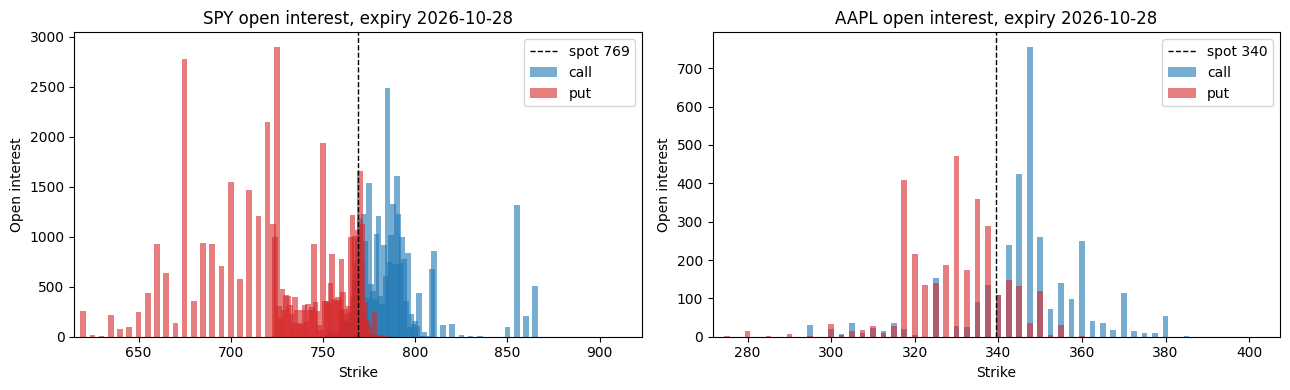

In [99]:
# Open interest by strike for the first expiry: where is the liquidity?
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, (t, d) in zip(axes, raw_data.items()):
    g = d[d["expiry"] == d["expiry"].min()]
    S = d["spot"].iloc[0]
    for kind, color in [("call", "tab:blue"), ("put", "tab:red")]:
        h = g[g["type"] == kind]
        ax.bar(h["strike"], h["openInterest"].fillna(0), width=S * 0.004, alpha=0.6, color=color, label=kind)
    ax.axvline(S, color="k", ls="--", lw=1, label=f"spot {S:.0f}")
    ax.set_xlim(S * 0.8, S * 1.2)
    ax.set_title(f"{t} open interest, expiry {g['expiry'].iloc[0]:%Y-%m-%d}")
    ax.set_xlabel("Strike")
    ax.set_ylabel("Open interest")
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "day1_open_interest.png", dpi=150)
plt.show()

## 5. Clean Option Data

Filters from the roadmap, applied in order:

| # | Filter | Why |
|---|---|---|
| 1 | `bid > 0` and `ask > bid` | No real quote / crossed market. |
| 2 | relative spread $(\text{ask}-\text{bid})/\text{mid} < 0.5$ | Too wide → mid price is meaningless. |
| 3 | $T > 7$ days | Very short maturities make IV unstable. |
| 4 | $0.7 \le K/S \le 1.3$ | Far wings are illiquid and noisy. |
| 5 | OTM only | Puts for $K<S$, calls for $K \ge S$ (see theory). |
| 6 | open interest $> 0$ | Nobody holds it → stale quote. |

If the snapshot has no live quotes (downloaded while the US market was closed), filters 1–2 are
replaced by `lastPrice > 0`, because every bid is zero.

In [100]:
def clean_chain(df, min_T=7/365, m_low=0.7, m_high=1.3, max_rel_spread=0.5, verbose=True):
    if has_live_quotes(df):
        quote_steps = [
            ("bid > 0 and ask > bid", lambda d: d[(d["bid"] > 0) & (d["ask"] > d["bid"])]),
            ("relative spread",       lambda d: d[(d["ask"] - d["bid"]) / d["mid"] < max_rel_spread]),
        ]
    else:
        quote_steps = [("lastPrice > 0 (no quotes)", lambda d: d[d["mid"] > 0])]
    steps = quote_steps + [
        ("min maturity",          lambda d: d[d["T"] > min_T]),
        ("moneyness range",       lambda d: d[(d["strike"] / d["spot"]).between(m_low, m_high)]),
        ("OTM only",              lambda d: d[((d["type"] == "call") & (d["strike"] >= d["spot"])) |
                                              ((d["type"] == "put") & (d["strike"] < d["spot"]))]),
        ("open interest > 0",     lambda d: d[d["openInterest"].fillna(0) > 0]),
    ]
    d = df.copy()
    log = []
    if verbose:
        print(f"{'start':24s} rows    {len(d):5d}")
    for name, f in steps:
        n0 = len(d)
        d = f(d)
        log.append({"filter": name, "removed": n0 - len(d), "left": len(d)})
        if verbose:
            print(f"{name:24s} removed {n0 - len(d):5d}   left {len(d):5d}")
    return d.reset_index(drop=True), pd.DataFrame(log)

In [101]:
clean_data, clean_logs = {}, {}
for t, d in raw_data.items():
    print(f"===== {t} =====")
    clean_data[t], clean_logs[t] = clean_chain(d)
    clean_data[t].to_parquet(DATA_DIR / f"clean_{t}.parquet", index=False)
    print(f"saved -> data/clean_{t}.parquet\n")

===== SPY =====
start                    rows     3579
lastPrice > 0 (no quotes) removed     0   left  3579
min maturity             removed   161   left  3418
moneyness range          removed   923   left  2495
OTM only                 removed  1119   left  1376
open interest > 0        removed    66   left  1310
saved -> data/clean_SPY.parquet

===== AAPL =====
start                    rows     1247
lastPrice > 0 (no quotes) removed     0   left  1247
min maturity             removed    66   left  1181
moneyness range          removed   660   left   521
OTM only                 removed   251   left   270
open interest > 0        removed     0   left   270
saved -> data/clean_AAPL.parquet



### Which filter is the most impactful?

In [102]:
impact = pd.concat({t: log.set_index("filter")["removed"] for t, log in clean_logs.items()}, axis=1).fillna(0).astype(int)
impact["SPY %"] = (impact["SPY"] / len(raw_data["SPY"]) * 100).round(1)
impact["AAPL %"] = (impact["AAPL"] / len(raw_data["AAPL"]) * 100).round(1)
display(impact)

for t, log in clean_logs.items():
    top = log.loc[log["removed"].idxmax()]
    print(f"{t}: most impactful filter = '{top['filter']}' "
          f"({top['removed']} rows, {top['removed'] / len(raw_data[t]):.0%} of the raw chain)")

,SPY,AAPL,SPY %,AAPL %
filter,,,,
lastPrice > 0 (no quotes),0,0,0.0,0.0
min maturity,161,66,4.5,5.3
moneyness range,923,660,25.8,52.9
OTM only,1119,251,31.3,20.1
open interest > 0,66,0,1.8,0.0


SPY: most impactful filter = 'OTM only' (1119 rows, 31% of the raw chain)
AAPL: most impactful filter = 'moneyness range' (660 rows, 53% of the raw chain)


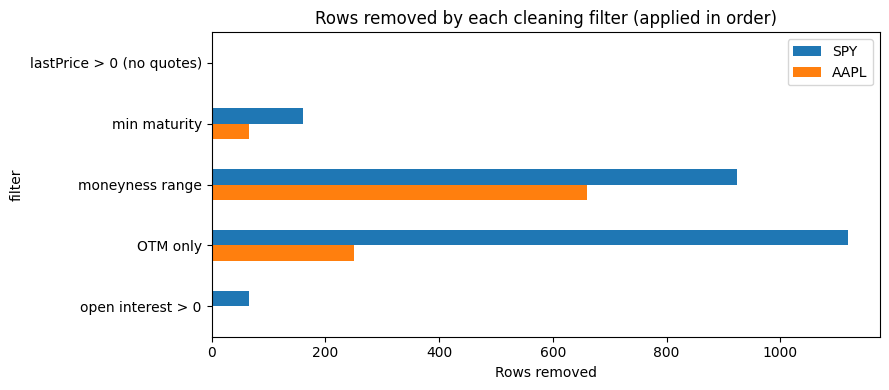

In [103]:
fig, ax = plt.subplots(figsize=(9, 4))
impact[["SPY", "AAPL"]].plot.barh(ax=ax, color=["tab:blue", "tab:orange"])
ax.invert_yaxis()
ax.set_xlabel("Rows removed")
ax.set_title("Rows removed by each cleaning filter (applied in order)")
plt.tight_layout()
plt.savefig(FIG_DIR / "day1_filter_impact.png", dpi=150)
plt.show()

**Interpretation.** Filters run *in order*, so each one only sees what the previous filters left.
The **OTM-only** filter is normally the biggest by construction: for every strike there is both a
call and a put, and we throw away the ITM half — roughly 50 % of what remains. Among the
*data-quality* filters, the **moneyness range** usually removes the most, because yfinance lists
many deep-wing strikes (especially for SPY) that are far from the spot. `bid > 0` removes the dead
quotes in the far wings, and the open-interest filter removes very little once the others have run.
(Check the printout above — the exact ranking depends on the day the data was downloaded.)

In [104]:
def bound_violations(d, r, q=0.0):
    """Count quotes whose mid lies outside the no-arbitrage bounds."""
    S, K, T = d["spot"], d["strike"], d["T"]
    disc_r, disc_q = np.exp(-r * T), np.exp(-q * T)
    is_call = d["type"] == "call"
    lower = np.where(is_call, np.maximum(S * disc_q - K * disc_r, 0), np.maximum(K * disc_r - S * disc_q, 0))
    upper = np.where(is_call, S * disc_q, K * disc_r)
    return int(((d["mid"] <= lower) | (d["mid"] >= upper)).sum())

for t in TICKERS:
    raw_t = raw_data[t]
    print(f"{t:5s} bound violations  raw (mid>0): {bound_violations(raw_t[raw_t['mid'] > 0], r):4d}   "
          f"clean: {bound_violations(clean_data[t], r):4d}")

SPY   bound violations  raw (mid>0):  378   clean:    0
AAPL  bound violations  raw (mid>0):  136   clean:    0


## 6. Visualize Option Prices

Mid price against strike for the first three expiries. Expected shape:
- **calls fall** as $K$ increases (the right to buy at a higher price is worth less);
- **puts rise** as $K$ increases (the right to sell at a higher price is worth more);
- longer expiries sit **above** shorter ones (more time value).

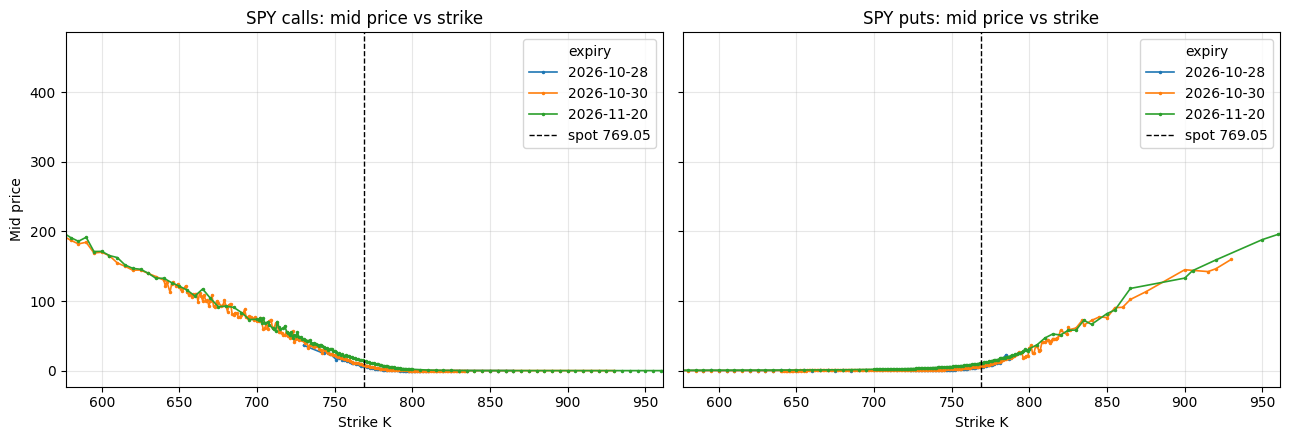

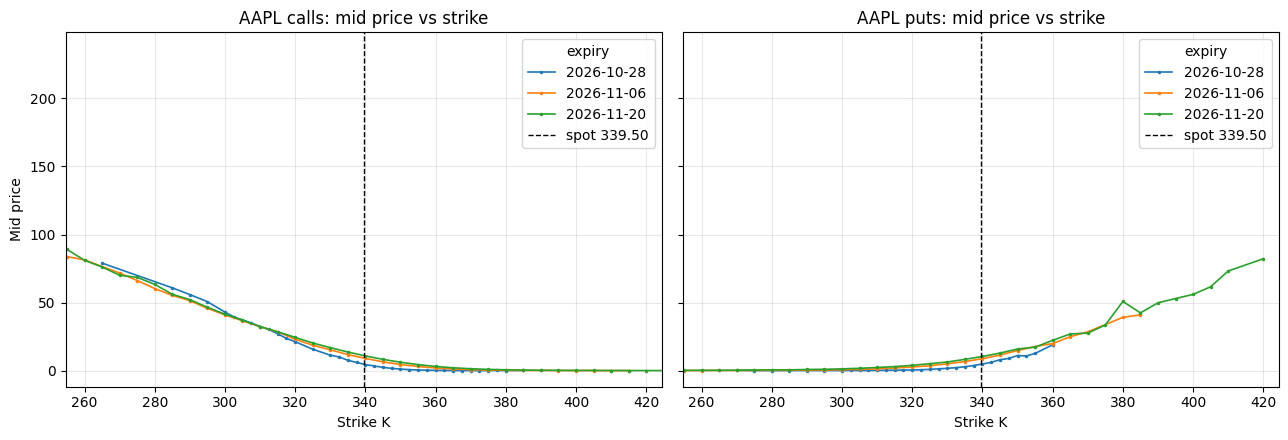

In [105]:
for t in TICKERS:
    d = raw_data[t]
    d = d[d["mid"] > 0]
    S = d["spot"].iloc[0]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, kind in zip(axes, ["call", "put"]):
        for exp in sorted(d["expiry"].unique())[:3]:
            g = d[(d["expiry"] == exp) & (d["type"] == kind)].sort_values("strike")
            ax.plot(g["strike"], g["mid"], marker=".", ms=3, lw=1.2, label=f"{pd.Timestamp(exp):%Y-%m-%d}")
        ax.axvline(S, color="k", ls="--", lw=1, label=f"spot {S:.2f}")
        ax.set_xlim(S * 0.75, S * 1.25)
        ax.set_title(f"{t} {kind}s: mid price vs strike")
        ax.set_xlabel("Strike K")
        ax.legend(title="expiry")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("Mid price")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"day1_prices_{t}.png", dpi=150)
    plt.show()

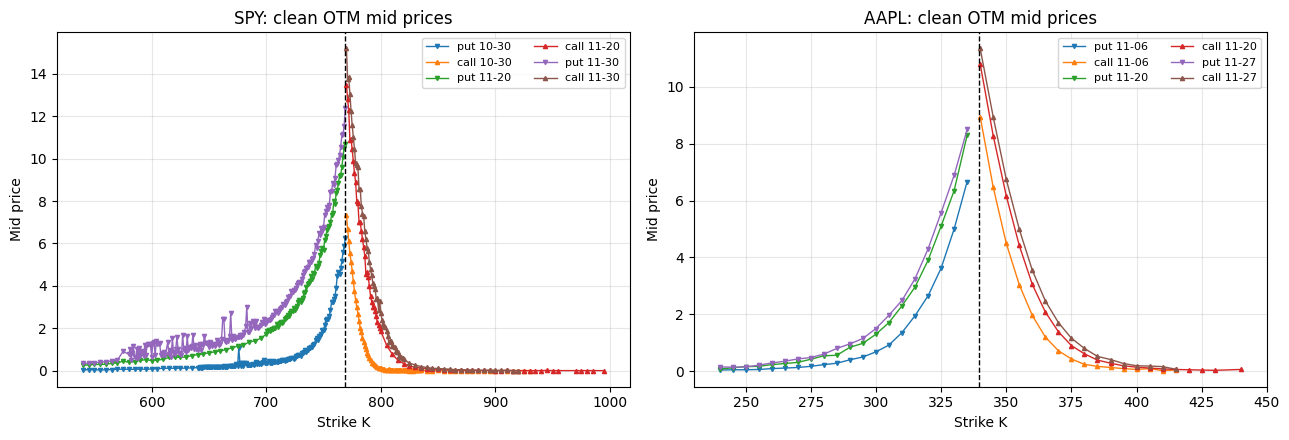

In [106]:
# Clean OTM quotes: puts on the left of spot, calls on the right -> the "V" shape used on Day 3
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, t in zip(axes, TICKERS):
    d = clean_data[t]
    S = d["spot"].iloc[0]
    for exp in sorted(d["expiry"].unique())[:3]:
        for kind, m in [("put", "v"), ("call", "^")]:
            g = d[(d["expiry"] == exp) & (d["type"] == kind)].sort_values("strike")
            ax.plot(g["strike"], g["mid"], marker=m, ms=3, lw=1,
                    label=f"{kind} {pd.Timestamp(exp):%m-%d}")
    ax.axvline(S, color="k", ls="--", lw=1)
    ax.set_title(f"{t}: clean OTM mid prices")
    ax.set_xlabel("Strike K")
    ax.set_ylabel("Mid price")
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "day1_clean_otm.png", dpi=150)
plt.show()

In [107]:
# Sanity check: are calls decreasing and puts increasing in K? (fraction of monotone steps)
for t in TICKERS:
    d = raw_data[t][raw_data[t]["mid"] > 0]
    res = {}
    for kind, sign in [("call", -1), ("put", 1)]:
        ok = tot = 0
        for _, g in d[d["type"] == kind].groupby("expiry"):
            diff = np.diff(g.sort_values("strike")["mid"].values)
            ok += int((sign * diff >= 0).sum())
            tot += len(diff)
        res[kind] = ok / tot
    print(f"{t:5s} calls decreasing in K: {res['call']:.1%}   puts increasing in K: {res['put']:.1%}")

SPY   calls decreasing in K: 74.2%   puts increasing in K: 73.4%
AAPL  calls decreasing in K: 85.2%   puts increasing in K: 85.9%


The few non-monotone steps come from stale or wide quotes in the deep wings — exactly what the
cleaning filters are for.

## 7. Put–Call Parity: Equation & Proof

### The equation
For European options on the same underlying, with the same strike $K$ and maturity $T$:
$$
\boxed{\,C - P = S e^{-qT} - K e^{-rT}\,}
$$
where $S$ is the spot, $r$ the risk-free rate and $q$ the continuous dividend yield.

### Proof (equal payoffs ⇒ equal prices)
Build two portfolios today.

| Portfolio | Contents | Cost today | Payoff at $T$ if $S_T > K$ | Payoff at $T$ if $S_T \le K$ |
|---|---|---|---|---|
| **A** | long 1 call, short 1 put | $C - P$ | $(S_T-K) - 0 = S_T - K$ | $0 - (K - S_T) = S_T - K$ |
| **B** | $e^{-qT}$ shares (dividends reinvested → 1 share at $T$), borrow $Ke^{-rT}$ | $Se^{-qT} - Ke^{-rT}$ | $S_T - K$ | $S_T - K$ |

Algebraically, for every possible $S_T$:
$$
(S_T - K)^+ - (K - S_T)^+ = S_T - K,
$$
because exactly one of the two terms is non-zero (or both are zero when $S_T = K$).

So A and B pay **exactly the same amount in every state of the world**. If their prices today were
different, we could buy the cheap one and sell the expensive one, pocket the difference now, and
owe nothing at $T$ — a riskless profit (**arbitrage**). Ruling out arbitrage forces
$$
C - P = Se^{-qT} - Ke^{-rT}. \qquad \blacksquare
$$

The proof uses **no model** at all — no volatility, no distribution for $S_T$ — only that the
payoffs match. That is why put–call parity holds for any model (Black–Scholes or not).

### What it means financially
- **A call and a put are not independent.** Once you know one price (and $S, K, r, q$), the other is
  fixed: $P = C - Se^{-qT} + Ke^{-rT}$.
- **Long call + short put = a synthetic forward.** It is like agreeing today to buy the stock at $K$
  on date $T$; its value is the discounted forward minus the discounted strike,
  $e^{-rT}(F - K)$ with $F = Se^{(r-q)T}$.
- **Same implied volatility for calls and puts.** Because $C$ and $P$ differ by a model-free
  amount, a call and a put with the same $(K,T)$ must have the same Black–Scholes IV. This is why we
  can use only OTM options (puts below spot, calls above) and still build one surface.
- **Implied forward (Day 3).** Rearranged, $C - P = e^{-rT}(F - K)$ is linear in $K$; regressing
  $C-P$ on $K$ gives the market's discount factor and forward — including dividends — without
  guessing $q$.
- **Arbitrage check.** If market quotes break parity by more than the bid–ask spread, one of the
  quotes is stale or there is a (usually tiny, short-lived) arbitrage.
- **American options (SPY, AAPL).** Early exercise makes parity an inequality,
  $Se^{-qT} - K \le C - P \le S - Ke^{-rT}$, but for OTM / near-ATM options and short maturities it
  holds closely, which we check below.

SPY   median |error| = 2.165   median error = -0.572
AAPL  median |error| = 0.748   median error = +0.339


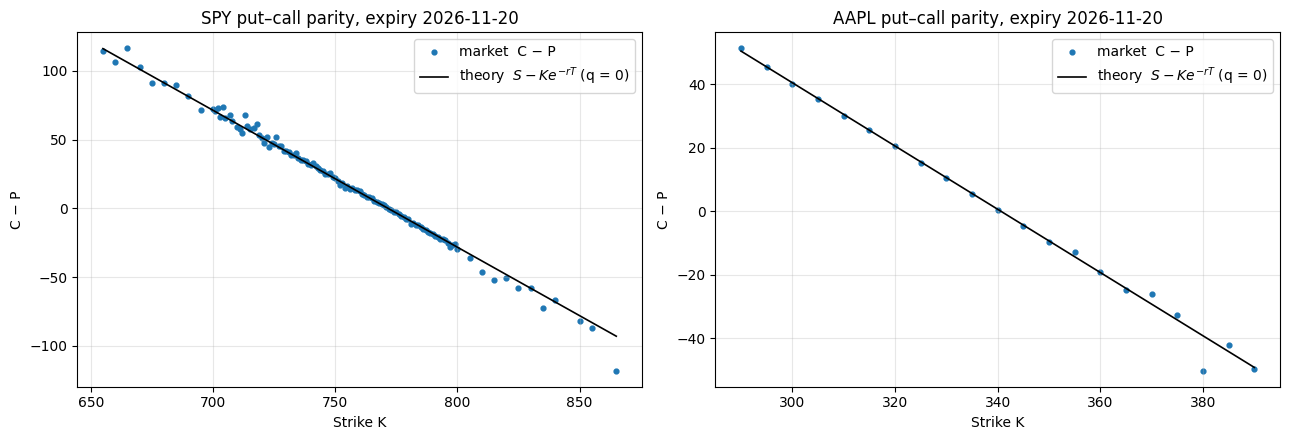

In [108]:
# Empirical check: C - P vs S - K e^{-rT} on strikes with both a call and a put quote
def parity_table(d, r, q=0.0):
    d = d[d["mid"] > 0]
    c = d[d["type"] == "call"].set_index(["expiry", "strike"])
    p = d[d["type"] == "put"].set_index(["expiry", "strike"])
    j = c[["mid", "spot", "T"]].join(p[["mid"]], lsuffix="_c", rsuffix="_p", how="inner").reset_index()
    j["C_minus_P"] = j["mid_c"] - j["mid_p"]
    j["theory"] = j["spot"] * np.exp(-q * j["T"]) - j["strike"] * np.exp(-r * j["T"])
    j["error"] = j["C_minus_P"] - j["theory"]
    return j

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, t in zip(axes, TICKERS):
    j = parity_table(raw_data[t], r)
    S = j["spot"].iloc[0]
    j = j[(j["strike"] / S).between(0.85, 1.15)]
    exp = sorted(j["expiry"].unique())[min(2, j["expiry"].nunique() - 1)]
    g = j[j["expiry"] == exp]
    ax.scatter(g["strike"], g["C_minus_P"], s=12, label="market  C − P")
    ax.plot(g["strike"], g["theory"], color="k", lw=1.2, label=r"theory  $S - Ke^{-rT}$ (q = 0)")
    ax.set_title(f"{t} put–call parity, expiry {pd.Timestamp(exp):%Y-%m-%d}")
    ax.set_xlabel("Strike K")
    ax.set_ylabel("C − P")
    ax.legend()
    ax.grid(alpha=0.3)
    print(f"{t:5s} median |error| = {j['error'].abs().median():.3f}   "
          f"median error = {j['error'].median():+.3f}")
plt.tight_layout()
plt.savefig(FIG_DIR / "day1_put_call_parity.png", dpi=150)
plt.show()

With $q=0$ the market line sits slightly **below** the theory line: that gap is the dividend
($Se^{-qT} < S$). Day 3 estimates it directly from this regression (the implied forward).

## 8. Day 1 Summary

In [109]:
rows = []
for t in TICKERS:
    raw_t, cl = raw_data[t], clean_data[t]
    rows.append({
        "ticker": t,
        "spot": round(raw_t["spot"].iloc[0], 2),
        "download date": f"{raw_t['download_date'].iloc[0]:%Y-%m-%d}",
        "raw rows": len(raw_t),
        "clean rows": len(cl),
        "kept %": round(len(cl) / len(raw_t) * 100, 1),
        "expiries (clean)": cl["expiry"].nunique(),
        "calls / puts": f"{(cl['type'] == 'call').sum()} / {(cl['type'] == 'put').sum()}",
    })
display(pd.DataFrame(rows).set_index("ticker"))
print(f"risk-free rate r = {r:.4f}")
print("\nFiles in data/:")
for f in sorted(DATA_DIR.iterdir()):
    print(f"  {f.name:32s} {f.stat().st_size / 1024:8.1f} KB")

,spot,download date,raw rows,clean rows,kept %,expiries (clean),calls / puts
ticker,,,,,,,
SPY,769.05,2026-10-21,3579,1310,36.6,9,439 / 871
AAPL,339.50,2026-10-21,1247,270,21.7,9,130 / 140


risk-free rate r = 0.0408

Files in data/:
  clean_AAPL.csv                       39.7 KB
  clean_AAPL.parquet                   16.8 KB
  clean_SPY.csv                       191.5 KB
  clean_SPY.parquet                    40.5 KB
  market_meta.json                      0.3 KB
  raw_AAPL.csv                        185.9 KB
  raw_AAPL.parquet                     32.6 KB
  raw_AAPL_20261021.csv               185.9 KB
  raw_AAPL_20261021.parquet            32.6 KB
  raw_SPY.csv                         571.0 KB
  raw_SPY.parquet                      78.3 KB
  raw_SPY_20261021.csv                571.0 KB
  raw_SPY_20261021.parquet             78.3 KB


**What was done today**
1. Reviewed calls, puts, strike, premium, expiry, payoffs, moneyness and no-arbitrage bounds.
2. Downloaded SPY and AAPL option chains (10 expiries each) and the risk-free rate, and **saved them in
   `data/`** — every later notebook loads these files instead of calling yfinance.
3. Explored bid, ask, strike, expiry and open interest.
4. Applied the six cleaning filters, printed the rows each removes, and identified the most impactful one.
5. Plotted call and put prices against strike: calls fall and puts rise with $K$.
6. Stated and proved put–call parity, explained its financial meaning and checked it on market data.

**Files produced**

| File | Content |
|---|---|
| `data/raw_SPY.parquet`, `data/raw_AAPL.parquet` | full raw chains (latest download) |
| `data/raw_<TICKER>_<YYYYMMDD>.parquet` | dated snapshots |
| `data/clean_SPY.parquet`, `data/clean_AAPL.parquet` | cleaned OTM quotes, ready for Day 2–3 |
| `data/market_meta.json` | risk-free rate, spot, download date |
| `figures/day1_*.png` | plots for the README |

**Next (Day 2):** Black–Scholes pricing and Greeks.

In [110]:
from pathlib import Path

data_dir = (Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()) / "data"

for f in data_dir.glob("*.parquet"):
    f.unlink()
    print("deleted", f.name)

print("\nFiles in data/:")
for f in sorted(data_dir.iterdir()):
    print("  ", f.name)


deleted raw_SPY.parquet
deleted clean_SPY.parquet
deleted clean_AAPL.parquet
deleted raw_SPY_20261021.parquet
deleted raw_AAPL.parquet
deleted raw_AAPL_20261021.parquet

Files in data/:
   clean_AAPL.csv
   clean_SPY.csv
   market_meta.json
   raw_AAPL.csv
   raw_AAPL_20261021.csv
   raw_SPY.csv
   raw_SPY_20261021.csv
